# Multi Layer Perceptron - Part 2

In [ ]:
# Makemore Part 3 - continuing MLP journey

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# pick the GPU if available (on AMD/ROCm builds of PyTorch the GPU is also exposed as 'cuda')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device, f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')
device = torch.device('cpu')
# Setting it to use CPU as for these small models, cpu is faster than overhead for moving data to GPU

using device: cpu 


In [ ]:
import os
data_path = '/content/sample_data/names.txt' if os.path.exists('/content/sample_data/names.txt') else 'names.txt'  # Colab or local
words = open(data_path).read().splitlines()

In [ ]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [ ]:
len(words)

32033

In [ ]:
# build vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


**Note:** we are not doing ```.emma.```  and then doing indexing. But instead we are just doing ```emma.```. This is beacuase the `.` at the beginning is being handled by the padded context of `[0,0,0]` that we start with.

The thing gets handled automatically without us having to set is manually

In [ ]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]    # crop and append

    X = torch.tensor(X, device=device)
    Y = torch.tensor(Y, device=device)
    print(X.shape, Y.shape)
    return X, Y

In [ ]:
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])            # 80%
Xdev, Ydev = build_dataset(words[n1:n2])        # 10%
Xte, Yte = build_dataset(words[n2:])            # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
# MLP revisited
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g)
b2 = torch.randn(vocab_size,                        generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

lossi = torch.stack(lossi).cpu().tolist()

      0/ 200000: 27.8817
  10000/ 200000: 2.9415
  20000/ 200000: 2.5069
  30000/ 200000: 2.7998
  40000/ 200000: 2.0261
  50000/ 200000: 2.5863
  60000/ 200000: 2.3420
  70000/ 200000: 2.0952
  80000/ 200000: 2.3454
  90000/ 200000: 2.2365
 100000/ 200000: 2.1080
 110000/ 200000: 2.3831
 120000/ 200000: 1.9898
 130000/ 200000: 2.4591
 140000/ 200000: 2.1910
 150000/ 200000: 2.1606
 160000/ 200000: 2.1811
 170000/ 200000: 1.7997
 180000/ 200000: 2.0962
 190000/ 200000: 1.8052


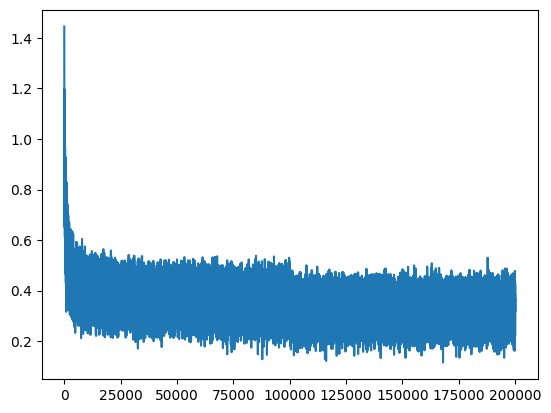

In [ ]:
plt.plot(lossi)


# PyTorch: `torch.no_grad()`

## 1. What is `torch.no_grad()`?

- `torch.no_grad()` is a PyTorch context manager/decorator that tells PyTorch that **gradient computation is not required** for the operations performed inside it.
- Normally, PyTorch keeps track of operations performed on tensors to construct a computational graph.
- This graph is maintained in anticipation of a potential backward pass (`.backward()`).
- However, there are situations where we only want to perform computations without calculating gradients, such as evaluating the model on the validation or test dataset.

## 2. How Does It Work?

When we use `torch.no_grad()` on a function:

- PyTorch assumes that the computations inside that function will never require gradients.
- It does not perform the usual autograd bookkeeping.
- It does not maintain the computational graph for a backward pass.
- It is almost as if the tensors created inside the function have `requires_grad=False`.

This makes computations more memory-efficient and faster because PyTorch doesn't need to track operations for gradient calculation.

### Using It as a Decorator

```python
@torch.no_grad()
def evaluate():
    # Operations inside this function
    # will not track gradients
    ...
```

### Using It as a Context Manager

We can also use it for a specific block of code:

```python
with torch.no_grad():
    # Operations inside this block
    # will not track gradients
    ...
```

## 3. When Should We Use It?

- During model evaluation on training, validation, or test datasets when we only want to calculate predictions and loss.
- During inference, when we want to generate predictions without performing backpropagation.
- Whenever we know that `.backward()` will not be called on the computations inside that block.

**Key takeaway:** Use `torch.no_grad()` when gradient computation is unnecessary. It avoids maintaining the computational graph and makes computations more efficient.


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    h = torch.tanh(embcat @ W1 + b1)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.127678871154785
val 2.1750576496124268


In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, then break
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

carlah.
amille.
khy.
myli.
taty.
skanden.
jazonen.
amerynchireei.
nellara.
chaiir.
kaleigh.
ham.
jorn.
quint.
salin.
alianni.
wanthoniearyn.
kai.
everusabee.
demiia.



## 2. Proper Initialization of a Neural Network

### The Problem with Our Current Initialization

The first thing Karpathy wants to scrutinize is the initialization of the neural network.

- Looking at the very first iteration (iteration 0), we observe a loss of approximately **27**.
- As training progresses, this loss rapidly comes down to around 1 or 2.
- This indicates that something is wrong with our initialization.

In neural network training, we should generally have a rough idea of what loss to expect at initialization. This depends on the loss function and the problem setup.

In our case, a loss of 27 is much higher than what we would expect.

### What Should the Initial Loss Be?

- We have 27 possible characters that could come next for any given training example.
- At initialization, we have no reason to believe that one character is more likely than another.
- Therefore, we would expect the neural network to initially produce a **uniform probability distribution** over all 27 characters.

The probability assigned to each character should approximately be:

$$
P(\text{character}) = \frac{1}{27}
$$

Since our loss is the negative log probability of the correct character:

$$
L = -\log P(\text{correct character})
$$

The expected initial loss should be:

$$
L = -\log\left(\frac{1}{27}\right)
$$

$$
L = \log(27) \approx 3.29
$$

So we expect an initial loss of approximately **3.29**, not 27.

### Why Are We Getting a Loss of 27?

- At initialization, our neural network is producing badly configured probability distributions.
- Some characters are receiving very high probabilities, while others are receiving very low probabilities.
- In other words, the network is making very confident predictions even though it hasn't learned anything yet.
- Sometimes it is confidently wrong, which results in a very high loss.

Ideally, at initialization, the network should not be overly confident about any particular character.

## 3. Understanding the Problem with a Smaller Example

Let's consider a simpler example with only **four possible characters**.

### Case 1: All Logits Are Zero

Suppose the neural network produces four logits:

$$
\text{logits} = [0, 0, 0, 0]
$$

When we apply softmax:

$$
P_i = \frac{e^{z_i}}{\sum_j e^{z_j}}
$$

Since all logits are zero:

$$
e^0 = 1
$$

Therefore, the resulting probability distribution is:

$$
P = [0.25, 0.25, 0.25, 0.25]
$$

This is a uniform distribution.

It doesn't matter whether the correct label is 0, 1, 2, or 3. Every character receives exactly the same probability.

For example, if the correct label is 2:

$$
L = -\log(0.25)
$$

$$
L = \log(4) \approx 1.38
$$

This is the expected initial loss for a classification problem with four equally likely classes.

### Case 2: Manipulating the Logits

Now let's start changing the logits.

- If the correct character happens to receive a high logit, we assign it a high probability and record a low loss.
- However, it is much more likely that some other character will receive the high logit.
- In that situation, the network becomes very confident about the wrong prediction, resulting in a much higher loss.

This is the problem with having extreme logits at initialization.

### Case 3: Randomly Initialized Logits

Karpathy demonstrates this using PyTorch:

```python
logits = torch.randn(4)

probs = torch.softmax(logits, dim=0)

loss = -probs[2].log()

print(logits)
print(probs)
print(loss)
```

Here:
- `torch.randn(4)` generates four normally distributed random numbers.
- These numbers are used as logits.
- We apply softmax to obtain probabilities.
- We calculate the negative log probability of the correct class (class 2).

Because these randomly initialized logits are generally not identical, the resulting probability distribution is not necessarily uniform.

### Case 4: Making the Logits More Extreme

Now suppose we multiply the randomly generated logits by 10:

```python
logits = torch.randn(4) * 10

probs = torch.softmax(logits, dim=0)

loss = -probs[2].log()

print(logits)
print(probs)
print(loss)
```

Multiplying by 10 makes the logits much more extreme.

As a result:

- The softmax distribution becomes much more concentrated.
- One character can receive an extremely high probability.
- The remaining characters receive probabilities close to zero.
- If the correct character is not the one receiving the highest probability, we get a very high loss.

If the logits become even more extreme, we can encounter extraordinarily large losses, potentially even infinity.

**Key takeaway:** Random initialization that produces excessively large logits can cause the network to make very confident but incorrect predictions even before training begins.

## 4. What Should the Logits Look Like at Initialization?

We want the logits to be approximately zero when the network is initialized.

More precisely, **all the logits should be equal**, so that softmax produces a uniform probability distribution.

For example:

$$
[0, 0, 0, 0]
$$

produces:

$$
[0.25, 0.25, 0.25, 0.25]
$$

Interestingly, the logits don't necessarily have to be zero.

For example:

$$
[1, 1, 1, 1]
$$

also produces exactly the same uniform probability distribution because softmax normalizes the exponentiated logits.

This is because adding or subtracting the same constant from every logit does not change the softmax probabilities.

However, by symmetry, we generally want the logits to be centered around zero rather than all having some arbitrary positive or negative value.

### Key Takeaway

At initialization, we want:

1. The logits to be approximately equal (ideally close to zero).
2. The softmax output to be approximately uniform.
3. The initial loss to be close to the expected loss for a uniform distribution.

For our 27-character classification problem:

$$
L_{\text{initial}} = \log(27) \approx 3.29
$$

A loss of 27 indicates that our network is producing excessively confident and poorly calibrated predictions right from initialization.

**Next:** We need to inspect our neural network and identify exactly where this initialization problem is coming from.


In [ ]:
1/27

0.037037037037037035

In [ ]:
-torch.tensor(1/27).log()

tensor(3.2958)

In [ ]:
# 4 dimensional example of the issue
logits = torch.tensor([0.0, 0.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
print(probs)        # tensor([0.2500, 0.2500, 0.2500, 0.2500]), This is a uniform distribution

loss = -probs.log().mean() # mean is the same as all the individual probabilities as this is a uniform distribution.

print(loss)

tensor([0.2500, 0.2500, 0.2500, 0.2500])
tensor(1.3863)


In [ ]:
# So, we want this kind of uniform initial distribution for the softmax.

# Hence, we multiply b2 with 0 to make it all 0 and
# Multiply W2 with a very small number like 0.01.
# Why not multiply W2 with 0? -
# Andrej says because we want a little entropy in the weights.
# I remember Claude saying that initializing weights to all zeros, prevents learning beacuse all weights move similarly or something.

# It wasn't claude, it was ChatGPT and here's what he said

If neurons start with identical weights, they can learn identical things and receive identical gradients, preventing them from developing different representations.

In [ ]:
# If we get lucky with the intialization, ie the logit for the actual one hot true label is 5.0. Assuming the correct classification was the 3rd element.
logits = torch.tensor([0.0, 0.0, 5.0, 0.0])
probs = torch.softmax(logits, dim=0)
print(probs)        # tensor([0.0066, 0.0066, 0.9802, 0.0066])

loss = -probs[2].log().mean() # 3rd element, ie index = 2 is the correct class
print(loss)

tensor([0.0066, 0.0066, 0.9802, 0.0066])
tensor(0.0200)


In [ ]:
# More likely is we get unlucky, ie one of the other classes gets a high logit, in this case we'll have a rather high loss
logits = torch.tensor([0.0, 5.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
print(probs)        # tensor([0.0066, 0.0066, 0.9802, 0.0066])

loss = -probs[2].log().mean() # 3rd element, ie index = 2 is the correct class
print(loss)

tensor([0.0066, 0.9802, 0.0066, 0.0066])
tensor(5.0200)


In [ ]:
# If we intialized logits from a random distribution,(for example sake). Logit will always come from actial calcuation, they are not initialized explicitly like weights.
logits = torch.randn(4)
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log().mean() # 3rd element, ie index = 2 is the correct class
logits, probs, loss

(tensor([-0.0095,  0.9311, -0.5971,  0.0910]),
 tensor([0.1915, 0.4904, 0.1064, 0.2117]),
 tensor(2.2406))

In [ ]:
# The loss above is not too high because we are sampleing the logits from a normal distribution with mean 0 and std dev = 1. But what happens if we multiply the logits by 10

In [ ]:
logits = torch.randn(4) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log().mean() # 3rd element, ie index = 2 is the correct class
logits, probs, loss

(tensor([19.9560,  7.9639,  1.7402,  0.4038]),
 tensor([9.9999e-01, 6.1928e-06, 1.2273e-08, 3.2254e-09]),
 tensor(18.2158))

In [ ]:
# It is very unlikely that you'll guess the correct bucket and you're constantly guess the wrong class very confidently, (we say confidently guessing th wrong  class because we are assigning very high logit to the wrong class), and consequently getting a very high loss.

In [ ]:
# If your logits are more extreme, you might even get infinite loss
logits = torch.randn(4) * 100
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log().mean() # 3rd element, ie index = 2 is the correct class
logits, probs, loss

(tensor([-18.1266, 103.2954, -14.7314, -15.3280]),
 tensor([0., 1., 0., 0.]),
 tensor(inf))

#### So we want the logits to be roughly 0 when the network is initialized

**Logits** is a special name for a pre-activation. It applies to the $z$ that is about to be fed into a softmax (or sigmoid) to become probabilities.

The name comes from log-odds: $\text{logit}(p) = \ln\frac{p}{1-p}$ is the inverse of the sigmoid.

In [ ]:
# Let's see where things go wrong.

In [ ]:
# reinitialize the weights, then in the training loop break after the very first iteration

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g)
b2 = torch.randn(vocab_size,                        generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

    break

      0/ 200000: 27.9729


In [ ]:
# intial loss is 27 is very high

In [ ]:
logits[0] # checking the logits of the very first example

tensor([ -2.4900,  35.2324, -12.6748,   5.4072,  16.6217, -11.7084,  -1.3984,
          1.2415,   9.2099,  11.3467,  13.6244,  -9.2524,   4.4376, -24.5945,
         -9.7140,   1.2474,  -9.5716, -13.7630, -23.2873,  -1.3743,  24.5218,
         16.1647,  16.6487, -10.9441, -21.5436,   7.2546,  11.4128],
       grad_fn=<SelectBackward0>)

In [ ]:
# We see that the logits take up very extreme values and that's what creating the fake confidence and incorrect answers and ery high loss of 27.

# These logits should be much much closer to 0


## 5. Fixing the Initialization: Making Logits Smaller

Now that we understand why the initial loss is too high, let's inspect the actual neural network and identify where the problem is coming from.

### Step 1: Inspect the Initial Logits

- Karpathy reinitializes the neural network and runs only the first iteration to inspect the initial loss.
- The initial loss is approximately **27**, whereas we expect something close to 3.29.
- If we inspect the first row of the logits, we can see that they contain some very extreme values.

```python
logits[0]
```

These extreme logits are creating fake confidence in incorrect predictions.

The network is assigning very high probabilities to some characters and very low probabilities to others, even though it hasn't learned anything yet.

**What we want:** The logits should be much closer to zero so that the resulting softmax distribution is approximately uniform.

### Step 2: Understand Where the Logits Come From

Recall that our output layer calculates the logits as:

$$
\text{logits} = hW_2 + b_2
$$

Where:
- $h$ represents the hidden-layer activations.
- $W_2$ represents the weights connecting the hidden layer to the output layer.
- $b_2$ represents the output-layer biases.

There are two sources contributing to the logits:

1. The bias term $b_2$.
2. The matrix multiplication $hW_2$.

We need to control both of them.

### Step 3: Initialize the Output Biases to Zero

Currently, we initialize $b_2$ with random values.

However, since we want the initial logits to be close to zero, we don't want to introduce random values through the bias term.

Therefore, we initialize the output biases to zero:

```python
b2 = torch.randn(27) * 0.0
```

This ensures:

$$
b_2 = 0
$$

Now the logits are determined only by:

$$
\text{logits} = hW_2
$$

### Step 4: Scale Down the Output Weights

Even after setting the biases to zero, the matrix multiplication $hW_2$ can still produce large logits.

If we want the logits to be smaller, we can scale down the output weights.

For example, multiply all the elements of $W_2$ by 0.1:

```python
W2 = torch.randn(100, 27) * 0.1
```

Now, when we run the first iteration again, the initial loss gets much closer to our expected value of 3.29.

We can reduce the scale further:

```python
W2 = torch.randn(100, 27) * 0.01
```

Now the initial loss is approximately 3.32.

The logits are much closer to zero, and the resulting probability distribution is much closer to uniform.

### Step 5: Why Not Initialize the Weights to Exactly Zero?

At this point, we might wonder:

Why not simply initialize $W_2$ to zero?

That would give us exactly the initial logits we want:

$$
\text{logits} = h \times 0 + 0 = 0
$$

And consequently, we would get exactly the expected uniform probability distribution.

However, Karpathy avoids initializing weights to exactly zero because of a problem called **symmetry**.

- Neural network weights should generally be initialized to small random values rather than exactly zero.
- Random initialization helps break symmetry between neurons.
- If neurons start with identical weights, they can learn identical things and receive identical gradients, preventing them from developing different representations.

For this particular output layer, zero initialization might actually be acceptable. However, initializing weights to small random values is a safer general practice.

Therefore, Karpathy chooses:

$$
W_2 = \text{Random initialization} \times 0.01
$$

This gives us:
- Logits that are much closer to zero.
- An initial loss close to the expected value of 3.29.
- A small amount of randomness, which helps with symmetry breaking.

### Key Takeaway

The initial loss was excessively high because our output layer was producing extreme logits, resulting in overly confident predictions.

We fix this by:

1. Initializing the output biases to zero.
2. Scaling down the output weights to make the initial logits smaller.
3. Using small random weights instead of setting everything to exactly zero.

Our initial loss is now approximately 3.32, which is very close to the expected loss of:

$$
\log(27) \approx 3.29
$$

The network now starts from a much more sensible initialization.


In [ ]:
# How the initialization looks after changes

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

    break

      0/ 200000: 3.3221


In [ ]:
logits[0] # Inspecting the logits after first iteration

tensor([-0.0249,  0.3523, -0.1267,  0.0541,  0.1662, -0.1171, -0.0140,  0.0124,
         0.0921,  0.1135,  0.1362, -0.0925,  0.0444, -0.2459, -0.0971,  0.0125,
        -0.0957, -0.1376, -0.2329, -0.0137,  0.2452,  0.1616,  0.1665, -0.1094,
        -0.2154,  0.0725,  0.1141], grad_fn=<SelectBackward0>)

In [ ]:
# Intializing b2 to 0 and W2 to 0.01 gives a initial loss of 3.32 and when we inspect the logits, they are in much managable ranges

In [ ]:
# We don't use 0 as initlaization for weights W2 for symetry breaking
#Let's run out model now

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3221
  10000/ 200000: 2.1900
  20000/ 200000: 2.4196
  30000/ 200000: 2.6067
  40000/ 200000: 2.0601
  50000/ 200000: 2.4988
  60000/ 200000: 2.3902
  70000/ 200000: 2.1344
  80000/ 200000: 2.3369
  90000/ 200000: 2.1299
 100000/ 200000: 1.8329
 110000/ 200000: 2.2053
 120000/ 200000: 1.8540
 130000/ 200000: 2.4566
 140000/ 200000: 2.1879
 150000/ 200000: 2.1118
 160000/ 200000: 1.8956
 170000/ 200000: 1.8644
 180000/ 200000: 2.0326
 190000/ 200000: 1.8417


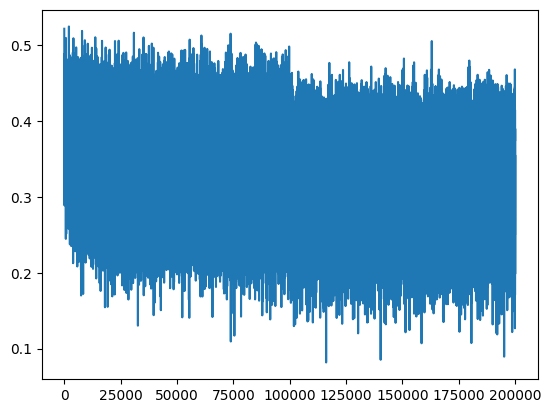

In [ ]:
plt.plot(lossi)


## 6. Effect of Proper Initialization on the Training Loss

Now that we have corrected the initialization by setting the output biases to zero and scaling down the output weights, let's run the optimization again and observe the loss.

### 1. The Hockey Stick Shape Disappears

Previously, our loss curve had a characteristic **hockey stick shape**:

- The loss started extremely high.
- It dropped very rapidly during the initial iterations.
- After that, it decreased more gradually.

With the corrected initialization, the loss starts at a reasonable value and decreases more smoothly.

**Why did the hockey stick shape disappear?**

Previously, the initial logits were extremely large because of the improperly initialized weights.

During the first few thousand optimization iterations, the network was primarily doing something relatively simple:

- Shrinking down the excessively large logits.
- Reducing the weights responsible for those extreme values.
- Only after that was it making meaningful progress in rearranging the logits and learning the actual patterns.

In other words, the initial rapid decrease in loss was largely coming from fixing the bad initialization rather than learning the actual task.

Now that we have corrected the initialization, we have removed this easy part of the optimization.

We are spending more of our optimization steps learning the actual neural network rather than simply shrinking down excessively large weights.

### 2. Improved Final Loss

There are two positive observations:

1. **Expected initial loss:** The network starts with an initial loss close to what we mathematically expect.
2. **No hockey stick:** The loss curve no longer shows the large initial drop caused by correcting the poorly initialized logits.

Additionally, the final loss is slightly improved.

Karpathy recalls the approximate previous results as:

- Previous training loss: 2.12
- Previous validation loss: 2.16

The corrected initialization produces a slightly better result because we spend more optimization steps actually training the neural network.

**Key takeaway:** Proper initialization is important not only because it gives us a sensible initial loss, but also because it allows optimization to focus on learning rather than correcting excessively large initial weights.



## 7. A Second Initialization Problem: Hidden Layer Activations

Even though our initial loss now looks good, there is another deeper problem lurking inside the neural network.

The logits are now behaving reasonably well, but the problem is with the hidden-layer activations, represented by $h$.

Recall our hidden layer:

$$
h = \tanh(XW_1 + b_1)
$$

We have already corrected the output layer initialization, but we haven't yet examined the values going into and coming out of the `tanh` activation.

In [ ]:
# Let's look at another problem
# This time the problem with first hidden layer

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#run for one time then break
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync
    break

      0/ 200000: 3.3221


In [ ]:
h

tensor([[ 0.8100, -0.8997, -0.9993,  ..., -0.9097, -1.0000,  1.0000],
        [-1.0000, -0.9571, -0.7145,  ...,  0.4898,  0.9090,  0.9937],
        [ 0.9983, -0.3340,  1.0000,  ...,  0.9443,  0.9905,  1.0000],
        ...,
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000],
        [-1.0000, -0.4385, -0.8882,  ..., -0.3316,  0.9995,  1.0000],
        [-1.0000,  0.9604, -0.1418,  ..., -0.1266,  1.0000,  1.0000]],
       grad_fn=<TanhBackward0>)

### 1. Inspecting the Hidden Activations

If we inspect the tensor $h$, we notice something concerning:

**Many of its elements are very close to either -1 or 1.**

Recall that `tanh` is a squashing function.

It takes arbitrary real-valued numbers and squashes them into the range:

$$
-1 \leq \tanh(x) \leq 1
$$

When the input values are moderate, `tanh` produces values smoothly distributed between -1 and 1.

However, when the input values become very large or very small, the output approaches the boundaries:

$$
\lim_{x \to +\infty} \tanh(x) = 1
$$

$$
\lim_{x \to -\infty} \tanh(x) = -1
$$

This is exactly what we are observing in our hidden activations.

In [ ]:
# Lot of these are just +1.0 or -1.0
# let's look at the histogram of h to get a better idea of the distribution of h

### 2. Visualizing the Distribution of Hidden Activations

Instead of inspecting the entire tensor manually, we can visualize the distribution of its values using a histogram.

Suppose:

- There are 32 examples in our mini-batch.
- Each example has 200 hidden-layer activations.

Therefore, the shape of $h$ is:

```
h.shape = (32, 200)
```

We can flatten this tensor into one long vector and plot its histogram.

```python
plt.hist(h.view(-1).tolist(), bins=50);
```

Here:
- `h.view(-1)` flattens the tensor into a one-dimensional vector.
- `.tolist()` converts it into a Python list of values.
- `plt.hist()` plots the distribution.
- `bins=50` divides the values into 50 histogram bins.

### 3. Observing the Histogram

The histogram reveals something concerning:

- A large proportion of the activations are concentrated around -1.
- A large proportion are concentrated around +1.
- Very few activations are distributed smoothly across the middle.

This tells us that the `tanh` function is heavily saturated.

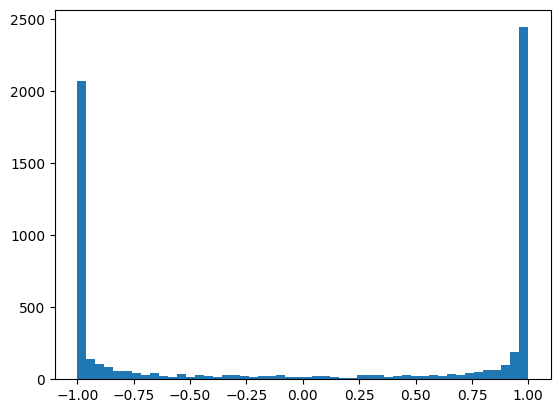

In [ ]:
plt.hist(h.view(-1).tolist(), bins =50);

### 4. Inspecting the Pre-Activations

To understand why this is happening, we need to inspect the values going into `tanh`, rather than just its outputs.

These values are called **pre-activations**.

Recall:

$$
H = \tanh(XW_1 + b_1)
$$

The pre-activations are:

$$
A = XW_1 + b_1
$$

We can visualize their distribution using another histogram.


In [ ]:
# Most values are -1 and +1. The tanh is very very active.
# let's look at hte preactivation of h

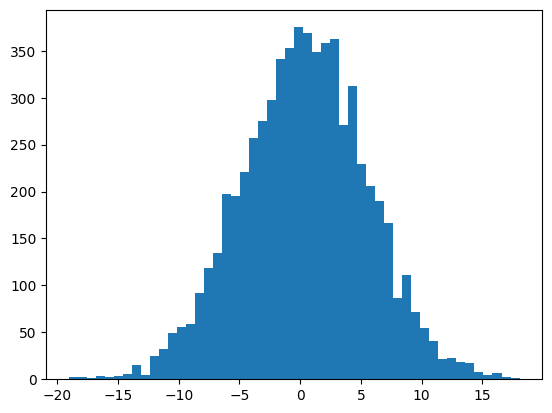

In [ ]:
plt.hist(hpreact.view(-1).tolist(), bins =50);


Karpathy observes that these pre-activation values have a very broad distribution, with values ranging approximately from -15 to +15.

This explains why the `tanh` outputs are concentrated around -1 and +1.

For example:

- Large positive pre-activations produce outputs close to +1.
- Large negative pre-activations produce outputs close to -1.
- Only moderate pre-activations produce outputs comfortably between -1 and +1.

Consequently, many neurons are operating in the saturated regions of the `tanh` function.

### 5. Why Is This a Problem?

At first glance, having activations between -1 and +1 might not seem problematic.

After all, isn't that exactly what `tanh` is supposed to do?

However, there is a deeper problem related to **backpropagation and gradient flow**.

When `tanh` becomes saturated near -1 or +1, its derivative becomes very small.

This means that gradients flowing backward through these neurons can become extremely small.

Karpathy is about to demonstrate why this is concerning for neural network training.

**Key takeaway:** We have fixed the output logits, but our hidden-layer activations are still heavily saturated. This can cause problems during backpropagation because saturated `tanh` neurons have very small gradients.



## 8. Why Saturated `tanh` Activations Are a Problem: Vanishing Gradients

We previously observed that most of our hidden-layer activations are concentrated around -1 and +1.

If you're familiar with backpropagation, this should immediately raise a concern.

The problem is that **when `tanh` outputs values close to -1 or +1, its gradients become very small, potentially stopping gradient flow through that neuron.**

Let's understand why.

### 1. Backpropagation Through `tanh`

Recall that during backpropagation, we start at the loss and propagate gradients backwards through the network.

In our neural network, the hidden layer contains 200 neurons for each example, and the `tanh` operation is applied element-wise.

We can revisit our Micrograd implementation from the first lecture:

```python
def tanh(self):
    x = self.data
    t = (np.exp(2*x) - 1) / (np.exp(2*x) + 1)
    out = Value(t, (self,), 'tanh')

    def _backward():
        self.grad += (1 - t**2) * out.grad

    out._backward = _backward

    return out
```

Here:

- `x` is the input to the `tanh` function.
- `t` is the output of `tanh(x)`.
- `t` lies between -1 and +1.
- `out.grad` is the gradient flowing backwards from the next operation.

The derivative of `tanh` is:

$$
\frac{d}{dx}\tanh(x) = 1 - \tanh^2(x)
$$

Since $t = \tanh(x)$, the local gradient is:

$$
1 - t^2
$$

Using the chain rule, the backward pass becomes:

$$
\text{self.grad} = (1-t^2)\times\text{out.grad}
$$

### 2. What Happens When `tanh` Outputs Values Close to +1 or -1?

Let's examine the derivative:

$$
\frac{d}{dx}\tanh(x) = 1-t^2
$$

**Case 1: When $t = 1$**

$$
1 - 1^2 = 0
$$

Therefore:

$$
\text{self.grad} = 0 \times \text{out.grad} = 0
$$

Regardless of the incoming gradient, we completely kill the gradient.

**Case 2: When $t = -1$**

$$
1 - (-1)^2 = 0
$$

Again:

$$
\text{self.grad} = 0
$$

The gradient stops flowing backwards through this `tanh` neuron.

**Case 3: When $t = 0$**

$$
1 - 0^2 = 1
$$

Therefore:

$$
\text{self.grad} = 1 \times \text{out.grad}
$$

The gradient passes through unchanged.

### 3. Why Does This Happen? Understanding the Shape of `tanh`

This makes intuitive sense when we look at the shape of the `tanh` function.

- When the output is close to +1, we are in the upper flat tail of the function.
- When the output is close to -1, we are in the lower flat tail.
- In these flat regions, changing the input barely changes the output.

Consequently, the loss is barely affected by changes to the input of that neuron.

Therefore, the derivative approaches zero.

In other words, the weights and biases feeding into a saturated `tanh` neuron have very little influence on the loss.

This is why the gradient becomes approximately zero.

### 4. The More Saturated the Neuron, the Smaller the Gradient

The derivative:

$$
1-t^2
$$

also tells us something important.

- When $t=0$, the gradient multiplier is 1. The gradient passes through unchanged.
- As $|t|$ increases towards 1, the gradient multiplier decreases.
- When $|t|=1$, the gradient multiplier becomes 0.

Therefore, the closer the activation is to either -1 or +1, the more the gradient gets squashed.

The gradient flowing backwards through `tanh` can only stay the same or decrease in magnitude.

### 5. The Vanishing Gradient Problem

Now recall what we observed in our hidden-layer activation histogram.

Most of the values in $h$ are concentrated around -1 and +1.

This means that many of our `tanh` neurons are operating in their saturated regions.

During backpropagation:

- Gradients flow backwards from the loss.
- They pass through the `tanh` activation.
- Many of these gradients get multiplied by values close to zero.
- Consequently, the gradients become extremely small or vanish entirely.

This is known as the **vanishing gradient problem**.

If most of the hidden activations are saturated, the gradients flowing through this layer can get destroyed, making it difficult for the network to learn effectively.


### 6. Measuring How Many Neurons Are Saturated

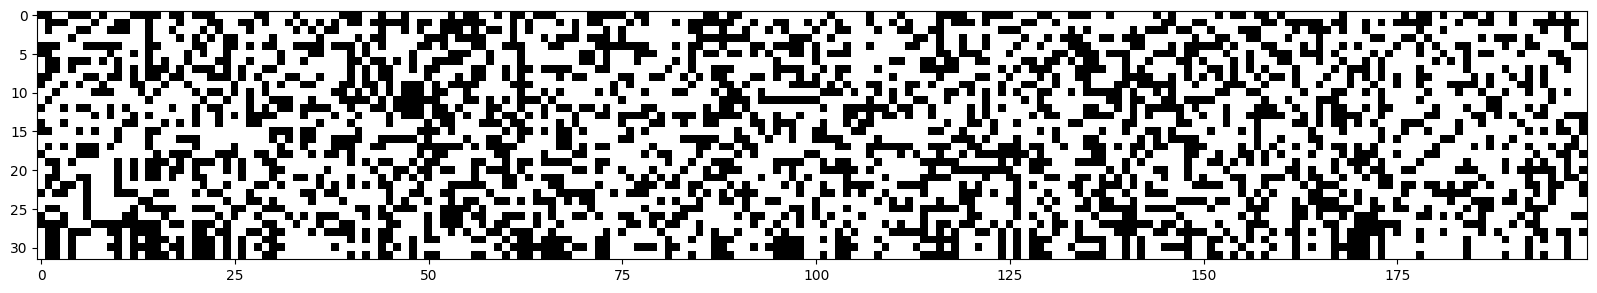

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')



Karpathy introduces a way to quantify how many hidden activations are in the flat regions of `tanh`.

We can examine the absolute values of $h$ and check how many exceed 0.9.

Conceptually:

```python
(h.abs() > 0.9)
```

This produces a Boolean tensor:

- `True` if the absolute activation is greater than 0.9.
- `False` otherwise.

The threshold of 0.9 is used to identify activations that are close to the saturated regions near -1 and +1.

Karpathy visualizes this Boolean tensor:

- White represents `True` (saturated or nearly saturated activation).
- Black represents `False` (activation not beyond the threshold).

This gives us a visual indication of how many neurons are operating in the flat regions of `tanh`.

### Key Takeaway

The problem with our hidden-layer initialization is not just that the activations are concentrated near -1 and +1.

The deeper problem is that **saturated `tanh` activations have derivatives close to zero, which destroys gradients during backpropagation.**

Recall:

$$
\boxed{\frac{d}{dx}\tanh(x)=1-\tanh^2(x)}
$$

This is why we need to pay attention not only to the initial loss and output logits, but also to the distribution of hidden-layer activations.


In [ ]:
# If all the examples give a white, ie we get a column of all whites, that neuron will never learn. It effectively becomes a dead neuron

In [ ]:
# No matter what you give through examples, this will always be +1 or -1, never learning anything, as gradients get zeroed out.

In [ ]:
# Same will apply to sigmoid.
# Also for ReLU.

# For reult out.grad will be exactly 0
# Dead ReLU, ->> if its output always stays below zero.


## 9. Dead Neurons and Saturation Across Different Activation Functions

### 1. Not All Saturated Neurons Are Completely Dead

Even though we observed that most of our `tanh` activations are concentrated around -1 and +1, some examples still activate neurons in the active region of `tanh`.

This means:
- Some gradients will still flow through these neurons.
- These neurons can still learn and update their weights.
- Their activations can change during optimization.

However, we can sometimes encounter a more serious situation called **dead neurons**.

### 2. Dead `tanh` Neurons

A `tanh` neuron is effectively dead when, regardless of which input example from the dataset we provide, its output is always either:

$$
\tanh(x) \approx 1
$$

or

$$
\tanh(x) \approx -1
$$

In this situation:

- The neuron is always operating in the flat, saturated region of `tanh`.
- Its derivative is approximately zero.
- Gradients flowing backwards through this neuron are effectively zeroed out.
- Its weights and biases cannot meaningfully learn.

Therefore, this neuron becomes effectively useless.

### 3. This Problem Is Not Limited to `tanh`

Several other activation functions can suffer from similar problems.

#### A. Sigmoid

The sigmoid activation function has the same saturation problem as `tanh`.

$$
\sigma(x) = \frac{1}{1+e^{-x}}
$$

Its output lies between 0 and 1.

- For very large positive inputs, the output approaches 1.
- For very large negative inputs, the output approaches 0.
- In both regions, the function becomes nearly flat.

Its derivative is:

$$
\sigma'(x) = \sigma(x)(1-\sigma(x))
$$

When the output approaches either 0 or 1, the derivative approaches zero.

Consequently, gradients become very small, potentially causing vanishing gradients.

#### B. ReLU

ReLU has a different but related problem.

Its definition is:

$$
\text{ReLU}(x) = \max(0,x)
$$

Unlike `tanh` and sigmoid, ReLU is not a squashing function.

- When the input is positive, ReLU acts as a pass-through.
- When the input is negative, ReLU outputs exactly zero.

Its derivative is:

$$
\text{ReLU}'(x) =
\begin{cases}
1 & x > 0 \\
0 & x < 0
\end{cases}
$$

The important difference is that ReLU has a completely flat region below zero.

When a ReLU neuron receives a negative pre-activation:

- Its output is zero.
- Its derivative is zero.
- The gradient flowing backwards through it is completely blocked.

This can result in a **dead ReLU neuron**.

### 4. What Is a Dead ReLU Neuron?

A ReLU neuron is considered dead when it never activates for any example in the dataset.

In other words, regardless of which training example we provide, its pre-activation remains negative.

Therefore:

$$
\text{ReLU}(x) = 0
$$

for every training example.

Since its derivative is also zero:

$$
\text{ReLU}'(x) = 0
$$

Its weights and biases never receive meaningful gradients.

Consequently, the neuron cannot learn and remains dead.

### 5. How Do Dead ReLU Neurons Occur?

There are two common ways this can happen.

**A. During initialization**

- Neural network weights and biases are initialized randomly.
- By chance, some neurons might receive pre-activations that are negative for every example in the dataset.
- Such neurons will never activate and can become dead right from initialization.

**B. During optimization**

Dead ReLU neurons can also develop while training.

For example, suppose we use an excessively high learning rate.

- A neuron receives a large gradient.
- Its weights and biases undergo a large update.
- The update can move the neuron outside the region where the training examples activate it.
- From that point onwards, no training example activates the neuron.
- Its gradients remain zero, and it stays dead.

Karpathy describes this as something like **permanent brain damage in the neural network**.

The neuron was initially capable of learning, but a large parameter update knocked it into a state where it can no longer learn.


No, a high learning rate can’t revive that neuron, and the numbers show why.

Your intuition would be right if the update were something like “high learning rate means big random kick.” But the update is $-\,\text{lr} \times \text{gradient}$, and for a dead neuron the gradient is exactly 0. A high learning rate multiplies zero by a big number, which is still zero.


In [ ]:
#-----------------------------------

**Setup**

Data: 4 examples with 3 features each. All the features are positive.

$$X = \begin{bmatrix} 1.0 & 2.0 & 0.5 \\ 2.0 & 1.0 & 1.0 \\ 0.5 & 3.0 & 2.0 \\ 1.5 & 0.5 & 1.0 \end{bmatrix}, \qquad y = (1.0,\ 1.5,\ 2.0,\ 0.8)$$
One hidden ReLU neuron: $z = w \cdot x + b$, and $a = \max(0, z)$
Output: $\hat{y} = v\,a + c$. The loss is mean squared error.
Initial values: $w = (0.5,\ 0.4,\ 0.3)$, $b = 0.1$, $v = 1$, $c = 0$

Backprop through the ReLU, for each example $i$:

$$dz_i = \underbrace{\frac{\partial L}{\partial a_i}}_{\text{upstream}} \cdot \underbrace{\mathbb{1}[z_i > 0]}_{\text{ReLU}'}, \qquad dw = \sum_i dz_i\, x_i, \qquad db = \sum_i dz_i$$
Step 0: a live neuron gets killed (lr = 1.0)
$z$ on the 4 examples is $(1.55,\ 1.80,\ 2.15,\ 1.35)$. All are positive, so the neuron is alive.
The gradients are $dw = (1.025,\ 1.063,\ 0.713)$ and $db = 0.775$.
The update gives:

$$w = (0.5 - 1.025,\ 0.4 - 1.063,\ 0.3 - 0.713) = (-0.525,\ -0.663,\ -0.413)$$
$$b = 0.1 - 0.775 = -0.675$$

All the weights and the bias are now negative, and every input is positive. So $z$ is negative on every example: $(-2.73,\ -2.80,\ -3.75,\ -2.21)$. The neuron is dead. This is the “large update knocks it out” case. It happened because the neuron was alive, so it had a nonzero gradient for the learning rate to scale up.

In [ ]:
#-----------------------------------


### 6. Identifying Dead ReLU Neurons

One way to identify dead ReLU neurons is to forward-propagate the entire training dataset through the network and inspect their activations.

If a particular ReLU neuron never activates for any training example, it is a dead neuron.

This is particularly worth checking when:
- Training with ReLU activation functions.
- Using excessively high learning rates.
- Observing neurons that consistently produce zero activations.

### 7. Other Activation Functions: Leaky ReLU and ELU

There are alternative activation functions that behave differently in their negative regions.

#### Leaky ReLU

Unlike standard ReLU, Leaky ReLU does not have a completely flat negative region.

Its definition is:

$$
f(x) =
\begin{cases}
x & x > 0 \\
\alpha x & x \leq 0
\end{cases}
$$

Where $\alpha$ is a small positive constant.

For negative inputs, the function still has a small non-zero slope.

Therefore:
- Gradients can flow even when the input is negative.
- Neurons are less likely to become permanently dead.
- The dead neuron problem is significantly reduced.

#### ELU (Exponential Linear Unit)

ELU is another commonly used activation function.

Its definition is:

$$
f(x) =
\begin{cases}
x & x > 0 \\
\alpha(e^x-1) & x \leq 0
\end{cases}
$$

ELU also has a non-zero gradient for finite negative inputs, although its derivative becomes small for very negative inputs.

Therefore, it can still experience saturation-related gradient problems, but it behaves differently from standard ReLU.

### 8. The Problem in Our Current Network

Coming back to our current `tanh` network:

- We observed that a large proportion of hidden activations are concentrated around -1 and +1.
- This means many neurons are operating in saturated regions.
- Their gradients are consequently being reduced significantly during backpropagation.

This is something we need to address through better initialization.

### Key Takeaway

Different activation functions have different ways of encountering gradient-flow problems:

| Activation | Problem |
|---|---|
| `tanh` | Saturation near -1 and +1 causes very small gradients |
| `sigmoid` | Saturation near 0 and 1 causes very small gradients |
| `ReLU` | Negative inputs produce exactly zero gradients, potentially causing dead neurons |
| `Leaky ReLU` | Non-zero negative slope helps reduce dead neuron problems |
| `ELU` | Avoids an exactly flat negative region, but can still experience saturation |

**Important:** Activation functions are not just about introducing non-linearity. Their derivatives directly influence how gradients flow through the neural network during backpropagation.


In [ ]:
# Saturation means there is less training for the neurons because they update less frequently

In [ ]:
# Let's look at another problem
# This time the problem with first hidden layer

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * 0.1
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#run for one time then break
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync
    break

      0/ 200000: 3.3069


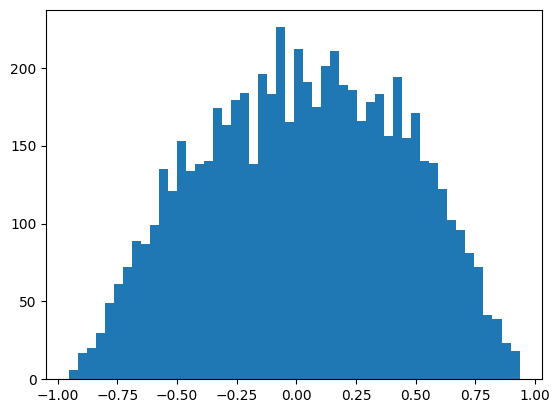

In [ ]:
plt.hist(h.view(-1).tolist(), bins =50);

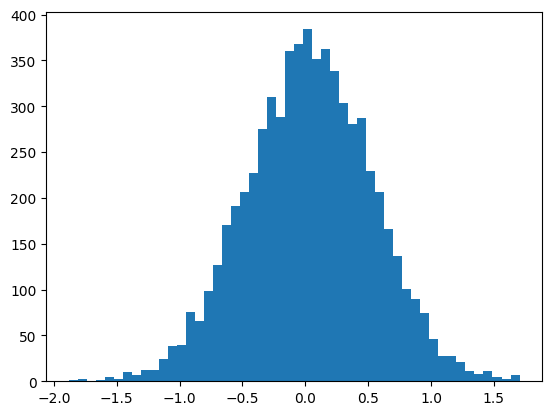

In [ ]:
plt.hist(hpreact.view(-1).tolist(), bins =50);

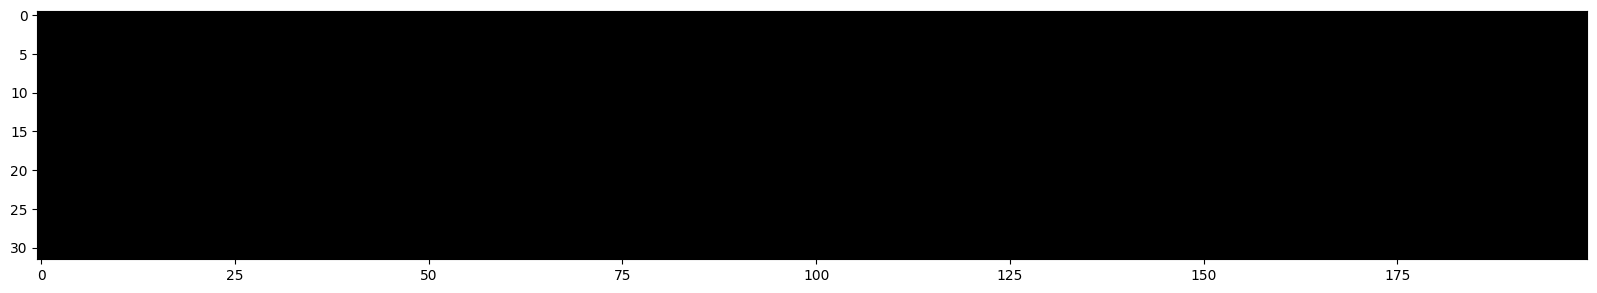

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')


## 10. Fixing Saturated `tanh` Activations Through Better Initialization

We previously observed that many hidden-layer activations were concentrated around -1 and +1.

This is undesirable because saturated neurons receive very small gradients during backpropagation. Consequently, their weights update less effectively, making it harder for these neurons to learn.

So how do we fix this?

### 1. Identify Where the Problem Comes From

Recall our forward pass:

```python
# Forward pass

emb = C[Xb]                         # [32, 3, 2]
embcat = emb.view(emb.shape[0], -1) # Concatenate the vectors

hpreact = embcat @ W1 + b1          # Hidden layer pre-activation
h = torch.tanh(hpreact)             # Hidden layer
logits = h @ W2 + b2                # Output layer
loss = F.cross_entropy(logits, Yb)
```

Let's focus on these two lines:

```python
hpreact = embcat @ W1 + b1
h = torch.tanh(hpreact)
```

Where:

- `embcat` contains the concatenated embeddings retrieved from the embedding matrix `C`.
- `W1` contains the weights connecting the input embeddings to the hidden layer.
- `b1` contains the hidden-layer biases.
- `hpreact` represents the pre-activations before applying `tanh`.
- `h` represents the resulting hidden-layer activations.

The embedding matrix `C` is initialized with random values, and we multiply these embeddings by `W1` and add `b1`.

The problem is that the resulting pre-activations are too far away from zero.

As a result, `tanh` receives extreme values and pushes most activations towards -1 or +1.

**Our objective is to make the pre-activations closer to zero**, just as we did with the output logits.

### 2. Initialize the Hidden-Layer Biases to Small Values

We don't want random biases to introduce unnecessarily large values into the pre-activations.

We can initialize the biases to zero:

```python
b1 = torch.randn(200) * 0.0
```

Alternatively, Karpathy suggests using a very small random value:

```python
b1 = torch.randn(200) * 0.001
```

This introduces a little bit of randomness and diversity into the initial activations of the `tanh` neurons.

He mentions that he sometimes prefers this small amount of variation because it can help optimization.

### 3. Scale Down the Hidden-Layer Weights

The other source of large pre-activations is the matrix multiplication:

$$
hpreact = embcat \times W_1 + b_1
$$

To reduce the magnitude of these pre-activations, we can scale down the weights.

For example:

```python
W1 = torch.randn(90, 200) * 0.1
```

Here, we multiply the randomly initialized weights by 0.1.

We can experiment with different scaling factors and observe the resulting distribution.

### 4. Inspect the New Distribution

After scaling down `W1`, Karpathy examines the histogram of the hidden-layer pre-activations and activations again.

Previously:
- The pre-activations had a very broad distribution.
- They ranged approximately from -15 to +15.
- Consequently, most `tanh` activations were saturated around -1 and +1.

After scaling down `W1` by 0.1:
- The pre-activations now range approximately between -1.5 and +1.5.
- The `tanh` activations are distributed much more smoothly.
- There are significantly fewer saturated neurons.

We can also inspect how many activations are close to the saturation regions:

```python
(h.abs() > 0.99)
```

Previously, many elements were `True`, indicating that their activations were very close to -1 or +1.

After correcting the initialization, there are almost no saturated activations above this threshold.

This is a much healthier distribution.

Karpathy then experiments with increasing the scaling factor slightly, from 0.1 to 0.2, to obtain a reasonable distribution of activations.

The idea is to find an initialization where the pre-activations are neither too large nor excessively small.



In [ ]:
# Let's look at another problem
# This time the problem with first hidden layer

n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * 0.2
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
#run for one time then break
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync
    break

      0/ 200000: 3.3135


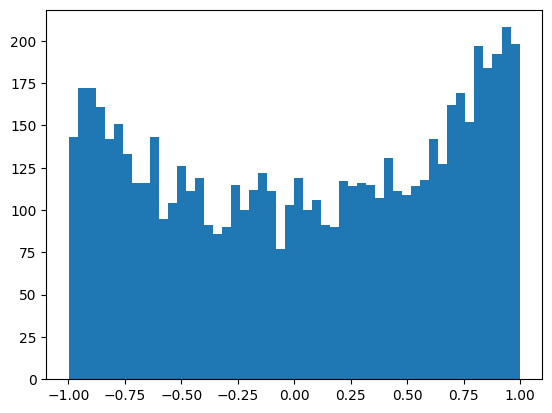

In [ ]:
plt.hist(h.view(-1).tolist(), bins =50);

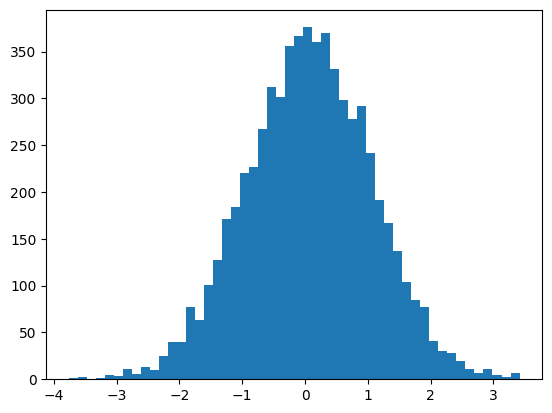

In [ ]:
plt.hist(hpreact.view(-1).tolist(), bins =50);

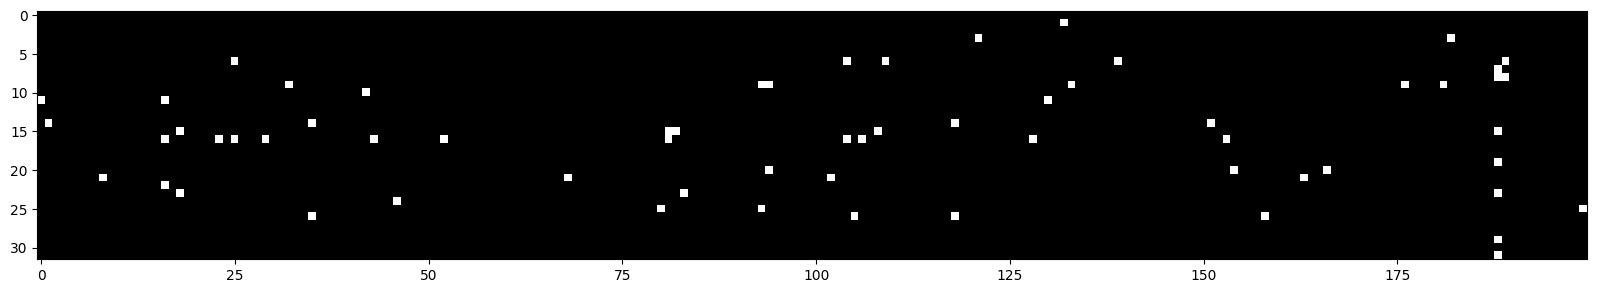

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')

### 5. Run the Complete Optimization Again

After finding a more reasonable initialization, Karpathy removes the break statement that was stopping execution after the first iteration.

He then reinitializes the network and runs the complete optimization process.

The resulting validation losses are approximately:

| Initialization / Model | Validation Loss |
|---|---:|
| Original initialization | 2.17 |
| Fixed output logits (W2 and b2) | 2.13 |
| Fixed saturated `tanh` activations (W1 and b1) | 2.10 |

We can see that correcting the initialization improves the final performance.

### 6. Why Does Better Initialization Improve Performance?

The reason is that we are spending more optimization steps doing productive training.

Previously, the network had two initialization problems:

1. **Overconfident softmax predictions:** The output logits were too extreme, causing the network to make very confident but incorrect predictions.
2. **Saturated `tanh` activations:** Many hidden neurons were operating in flat regions, causing gradients to become very small or vanish.

Consequently, a significant portion of the optimization was spent correcting these initialization problems rather than learning useful patterns.

By improving initialization:

- The initial softmax distribution is more reasonable.
- Hidden-layer activations are less saturated.
- Gradients can flow more effectively.
- More optimization steps contribute to actually learning the task.

This illustrates how understanding the internal activations and gradients of a neural network can help us improve its performance simply by choosing better initialization.

## 11. Why Initialization Becomes Even More Important in Deep Neural Networks

One important distinction Karpathy makes is that our current network is relatively small.

- We are working with a shallow neural network.
- It is essentially a one-hidden-layer multilayer perceptron (MLP).
- Because the network is shallow, its optimization problem is relatively easy and forgiving.

Even though our original initialization was quite poor, the network eventually learned.

It simply achieved a slightly worse result because some optimization steps were wasted correcting the initialization problems.

However, this is not necessarily true for deeper neural networks.

Imagine working with a network containing 50 layers.

In deeper networks:
- Gradients pass through many more layers.
- Problems with gradient flow can accumulate.
- Poor initialization can make optimization significantly more difficult.
- The network might barely train at all if initialization is sufficiently bad.

The deeper and more complex the network becomes, the less forgiving it can be to initialization problems.

### Key Takeaway

Initialization is not just about assigning random values to weights and biases.

We need to pay attention to:

1. The distribution of the initial logits.
2. The distribution of hidden-layer pre-activations.
3. The distribution of hidden-layer activations.
4. Whether neurons are saturated.
5. Whether gradients can flow effectively during backpropagation.

**The central lesson:** Good initialization helps ensure that the neural network starts in a state where gradients can flow and optimization can make productive progress from the very beginning.


In [ ]:
# Of course these 0.2, 0.01, 0.0, etc. are not to be set by hand .Let's see how to do that.

In [ ]:
# But first, a motivating example

tensor(-0.0077) tensor(0.9954)
tensor(-0.0109) tensor(3.0958)


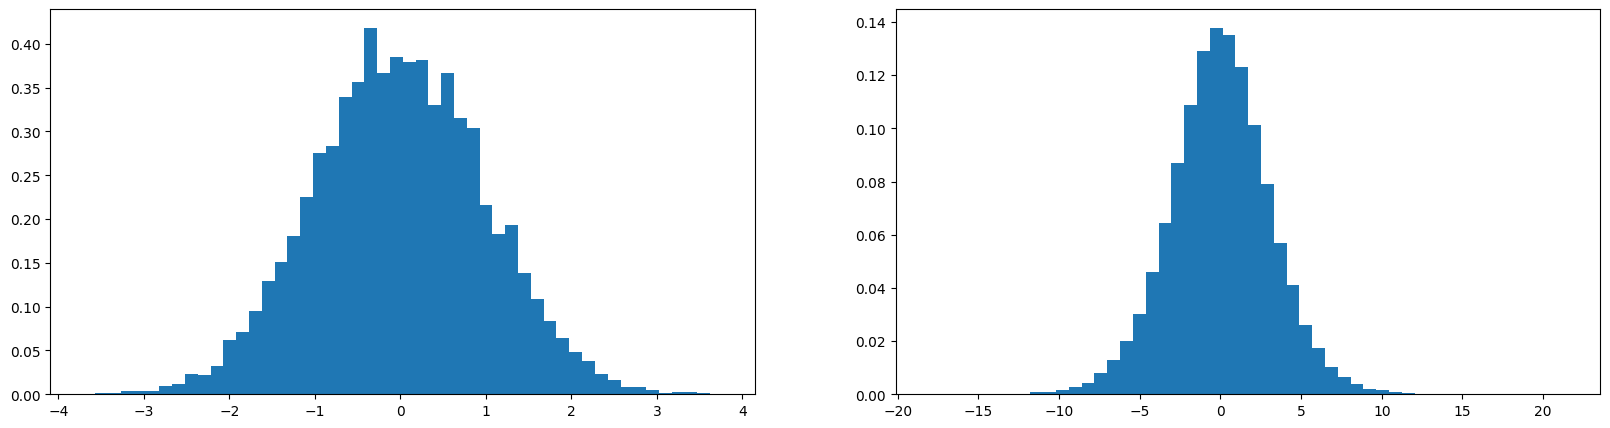

In [ ]:
x = torch.randn(1000, 10)   # [1000, 10] dim tensor (1000 examples, 10 features)
w = torch.randn(10, 200)    # [10, 200] dim tensor (hidden layer -> 200 neurons)
y = x @ w                   # [1000, 200] dim, preactivations
print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);

In [ ]:
# Gaussian is expanding, we don't want that. We want uint Gaussian throughout the Neural Net.

# How to preserve the Gaussian?

In [ ]:
# What to multiply to make the std dev of y = 1?
# ans is sqrt(fan_in)

# Here fan_in = 10, so mulitply 10**0.5

tensor(-0.0044) tensor(0.9865)
tensor(0.0018) tensor(0.9710)


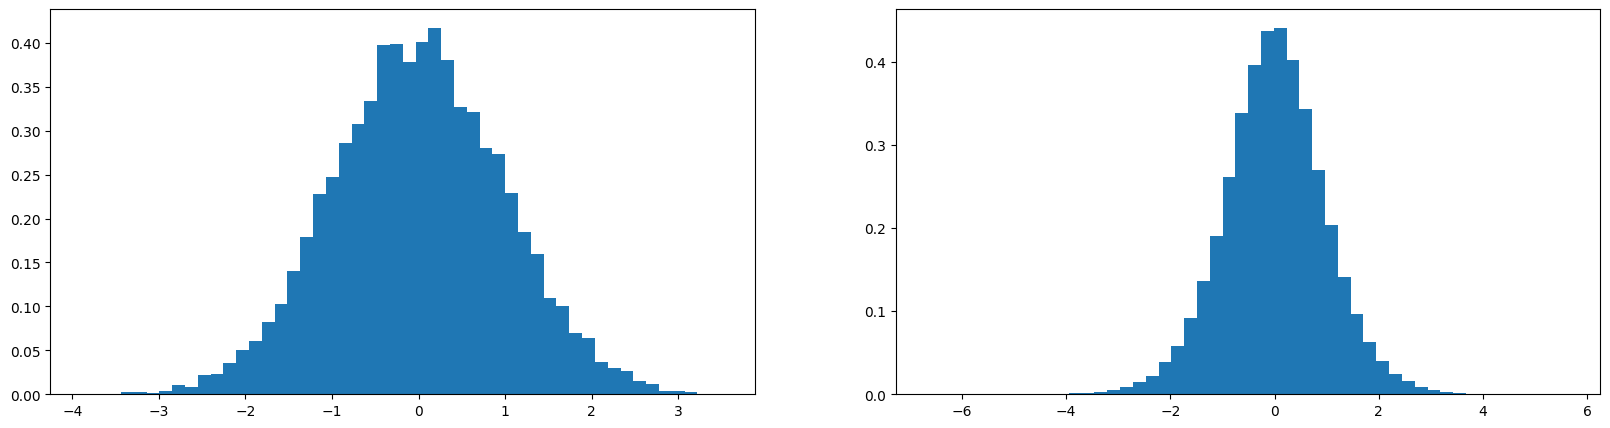

In [ ]:
x = torch.randn(1000, 10)   # [1000, 10] dim tensor (1000 examples, 10 features)
w = torch.randn(10, 200) / 10**0.5    # [10, 200] dim tensor (hidden layer -> 200 neurons)
y = x @ w                   # [1000, 200] dim, preactivations
print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);


## 12. Preserving the Standard Deviation Across Neural Network Layers

As we pass data through multiple layers of a neural network, the Gaussian distribution can expand or shrink. We want to preserve the distribution so that the standard deviation remains approximately constant throughout the network.

**How do we initialize the weights to make the standard deviation of the output equal to 1?**

The answer is to scale the weights by:


$$\frac{1}{\sqrt{\text{fan}_{\text{in}}}}$$

Here, `fan_in` is the number of input neurons to the layer. For example, if `fan_in = 10`, we multiply the randomly initialized weights by:

$$
\frac{1}{\sqrt{10}}
$$

### Kaiming Initialization

Kaiming et al. proposed the following initialization for ReLU networks:

$$
W = \mathcal{N}\left(0,\frac{2}{\text{fan}_{\text{in}}}\right)
$$

Equivalently, we multiply standard Gaussian random weights by:

$$
\sqrt{\frac{2}{\text{fan}_{\text{in}}}}
$$

The extra factor of 2 compensates for the behavior of ReLU: it throws away the negative side of the preactivations by setting negative values to zero.

With `tanh`, we use both positive and negative sides of the distribution, so we do not need that extra factor of 2.

Therefore, for `tanh`, we use:

$$
W = \mathcal{N}\left(0,\frac{1}{\text{fan}_{\text{in}}}\right)
$$

This helps preserve the variance of activations as they propagate through the network.



## 13. Gain in Weight Initialization

The Kaiming initialization formula includes a gain factor:

$$
W = \mathcal{N}\left(0,\frac{\text{gain}^2}{\text{fan}_{\text{in}}}\right)
$$

The gain depends on the activation function:

| Activation function | Recommended gain |
|---|---:|
| Linear / Identity | 1 |
| ReLU | $\sqrt{2}$ |
| Tanh | $\frac{5}{3}$ |

### Why Do We Need a Gain?

The gain compensates for the contraction caused by activation functions.

- **ReLU:** Sets all negative preactivations to zero, effectively discarding half of the distribution.
- **Tanh:** Squashes values into the range $[-1,1]$, squeezing the tails of the distribution toward the center.

Because these activation functions contract the distribution, we boost the weights slightly using a gain to compensate and help maintain a standard deviation close to 1.

### Why Initialization Is Less Fragile Today

Around seven years ago, when the paper was written, neural network training was more sensitive to initialization. We had to carefully inspect activation and gradient distributions, their ranges, and the gains used.

Modern innovations have made neural networks significantly more stable:

1. **Residual connections:** Help gradients flow through deep networks.
2. **Normalization layers:** Batch normalization, layer normalization, and group normalization stabilize activations.
3. **Better optimizers:** RMSProp and especially Adam improve optimization compared with basic SGD.

These innovations make precise initialization less critical than it used to be.

### Practical Recommendation

In practice, a simple approach is to initialize weights by dividing by the square root of `fan_in`:

$$
W = \frac{\text{randn}(\text{fan_in},\text{fan_out})}
{\sqrt{\text{fan_in}}}
$$

This is usually a reasonable starting point.

For a more precise initialization, PyTorch provides:

```python
torch.nn.init.kaiming_normal_()
```


In [ ]:
(torch.randn(10000) * 0.2).std()

tensor(0.2028)

In [ ]:
(5/3) / (30**0.5)

0.3042903097250923

In [ ]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

11897


In [ ]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

    hpreact = embcat @ W1 + b1 # hidden layer pre-activation (state of hidden layer before the activation function is applied)
    h = torch.tanh(hpreact)    # hidden layer
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3179
  10000/ 200000: 2.1910
  20000/ 200000: 2.3270
  30000/ 200000: 2.5396
  40000/ 200000: 1.9468
  50000/ 200000: 2.3331
  60000/ 200000: 2.3852
  70000/ 200000: 2.1173
  80000/ 200000: 2.3159
  90000/ 200000: 2.2010
 100000/ 200000: 1.8591
 110000/ 200000: 2.0881
 120000/ 200000: 1.9389
 130000/ 200000: 2.3913
 140000/ 200000: 2.0949
 150000/ 200000: 2.1458
 160000/ 200000: 1.7824
 170000/ 200000: 1.7249
 180000/ 200000: 1.9752
 190000/ 200000: 1.8614


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    h = torch.tanh(embcat @ W1 + b1)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0376641750335693
val 2.106989622116089


In [ ]:
# We use something that is semi-princpled (5/3) and can scale up, isntead of just eyeballing it.